# A prepayment model, fitted to Freddie Mac's loans

The database is a 2% sample of Freddie Mac's 30-year fixed-rate loans, 1999 to 2025, every month of each: what it owed, what it prepaid
(a payoff, or part of the balance paid early), and what a model looks at. `load_freddie_data/README.md` says how it is made.

The model is of the **smm**, the share of a loan's scheduled balance that it prepaid in a month (1 for a loan paid off), weighted by that balance,
so that over a pool it is the pool's smm, and the CPR is 1 - (1 - smm)^12. It is fitted two ways, on the same predictors
(`prepayment-predictors` in `lib/freddie_prepayment.lsp`):

- **loan by loan**: every month of every loan;
- **by groups**: the months of loans that are alike put together (each month, incentive to the nearest 0.25%, and band of age), each group's smm
  and the averages of its loans.

Both are fitted to the loans with a `sample_bucket` below 80, in the months before 2019, and tried on the other loans, in every month: before 2019
is the same time as the fit, and from 2019 on (the refinancing wave of 2020 and 2021, and the high rates after it) is a future it did not see.

In [1]:
(define conn (sqlite-open "/Users/morris/freddie_data/freddie_loans.db"))

conn

## Loan by loan

In [2]:
(define fit-loans (freddie-loan-months conn "sample_bucket < 80 AND period < '2019-01-01'"))
(define by-loan (fit-prepayment-model fit-loans))
(display (model-report by-loan))

Piecewise-linear spline model, with a logistic link, predicting y:
  predictors = 13
  incentive_bp: knots -100, 0, 50, 100, 150, 200, 300
  loan_age: knots 6, 12, 24, 36, 60, 120
  loan_size_k: knots 100, 200, 300
  credit_score: knots 680, 740
  current_ltv: knots 60, 80, 100
  sato: knots (none -- plain linear)
  burnout: knots 12
  investor: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  second_home: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  cash_out: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  refinance: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  winter: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  summer: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]

Coefficients (on the expanded basis):
  term                       co

## By groups

In [3]:
(define fit-groups (freddie-groups conn "part = 'fit' AND period < '2019-01-01'"))
(define by-group (fit-prepayment-model fit-groups))
(display (model-report by-group))

Piecewise-linear spline model, with a logistic link, predicting y:
  predictors = 13
  incentive_bp: knots -100, 0, 50, 100, 150, 200, 300
  loan_age: knots 6, 12, 24, 36, 60, 120
  loan_size_k: knots 100, 200, 300
  credit_score: knots 680, 740
  current_ltv: knots 60, 80, 100
  sato: knots (none -- plain linear)
  burnout: knots 12
  investor: knots (none -- plain linear)
  second_home: knots (none -- plain linear)
  cash_out: knots (none -- plain linear)
  refinance: knots (none -- plain linear)
  winter: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  summer: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]

Coefficients (on the expanded basis):
  term                       coefficient     std error    z value    p value
  intercept                     -15.0359      0.992114     -15.16   6.98e-52
  incentive_bp                0.00233824    0.00100663      2.323     0.0202
  incentive_bp (knot -100)    0.

## On the loans they were not fitted to

The CPR of the test loans, all of them together, month by month, and what each model says it was: the loan-by-loan model from each loan's month,
and the grouped one from each group's averages.

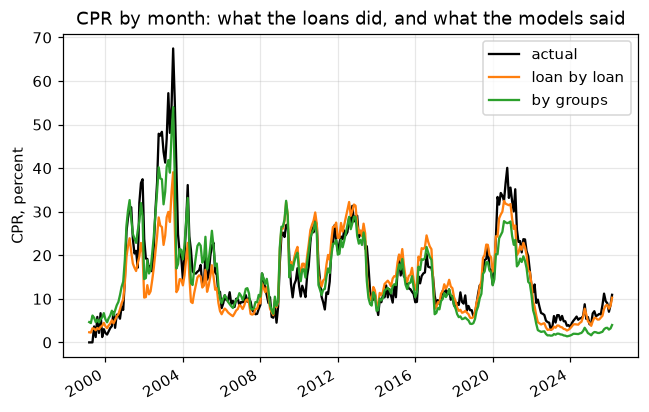

In [4]:
(define test-loans (freddie-loan-months conn "sample_bucket >= 80"))
(define test-groups (freddie-groups conn "part = 'test'"))
(plot-rate-by-month (list (list "loan by loan" by-loan test-loans)
                          (list "by groups" by-group test-groups))
                    "CPR")

How far each is from what the test loans did, on average over the months, in CPR: before 2019, the time it was fitted to, and from 2019 on.

In [5]:
(display-table (rate-misses (list (list "loan by loan" by-loan test-loans)
                                 (list "by groups" by-group test-groups))
                           (date 2019 1 1)
                           "CPR")
               '(("before 2019-01-01" ".2f") ("from 2019-01-01 on" ".2f")))

| model | before 2019-01-01 | from 2019-01-01 on |
|:---|---:|---:|
| loan by loan | 4.27 | 2.00 |
| by groups | 2.95 | 4.33 |

## The S-curves

What each model says a typical loan prepays at (`typical-prepayment-loan`: three years old, $250,000, a credit score of 750, 70% loan-to-value,
a purchase of a primary home, in spring or fall), against its incentive.

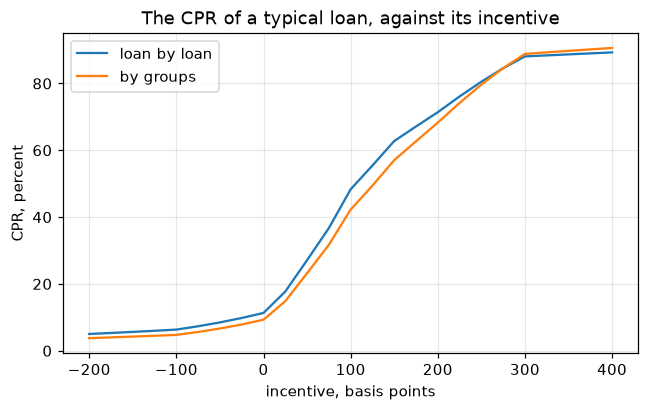

In [6]:
(plot-prepayment-s-curves (list (list "loan by loan" by-loan) (list "by groups" by-group)))

## Is the sample big enough?

The same model fitted to two halves of the loans, which have none in common: the loans with a `sample_bucket` below 40, and those from 40 to 79.
How far apart their S-curves are is how much the curve would change with a different sample of the same size; a sample twice the size would
move it by about 70% as much.

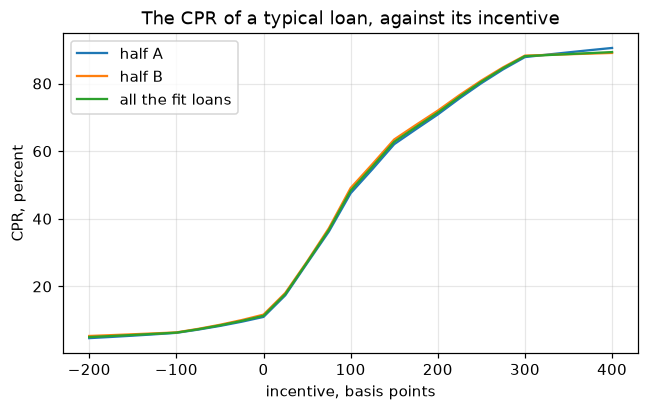

In [7]:
(define half-a (fit-prepayment-model (freddie-loan-months conn "sample_bucket < 40 AND period < '2019-01-01'")))
(define half-b (fit-prepayment-model (freddie-loan-months conn "sample_bucket >= 40 AND sample_bucket < 80 AND period < '2019-01-01'")))
(plot-prepayment-s-curves (list (list "half A" half-a) (list "half B" half-b) (list "all the fit loans" by-loan)))

## The model for the deals

The model that a deal's pricing speed of type MODEL is a share of (`freddie-prepayment-model`, in `lib/freddie_prepayment.lsp`): fitted loan by loan to
half of the loans, in every month, 2019 to 2025 too (the two halves above show that half of them is plenty), and saved beside the library, in
`lib/freddie_prepayment_fit.json`, which the deals read.

In [8]:
(define for-deals (fit-prepayment-model (freddie-loan-months conn "sample_bucket < 40")))
(save-freddie-prepayment-fit for-deals "../lib/freddie_prepayment_fit.json")
(display (model-report for-deals))

Piecewise-linear spline model, with a logistic link, predicting y:
  predictors = 13
  incentive_bp: knots -100, 0, 50, 100, 150, 200, 300
  loan_age: knots 6, 12, 24, 36, 60, 120
  loan_size_k: knots 100, 200, 300, 500
  credit_score: knots 680, 740
  current_ltv: knots 60, 80, 100
  sato: knots (none -- plain linear)
  burnout: knots 12
  investor: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  second_home: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  cash_out: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  refinance: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  winter: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  summer: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]

Coefficients (on the expanded basis):
  term                    